# Car Price Analysis and Prediction with Multiple Linear Regression

**Course:** BUAN 660 Applied Statistics, Sacred Heart University (Group 1)

**Goal:** find which car features drive price, measure how much each one matters, and check how well a multiple linear regression model predicts the price of cars it has not seen.

**Dataset:** `CarPrice_Assignment.csv`, 205 cars with 25 attributes (Kaggle).

**Workflow**

1. Clean the data (drop the ID column, check for missing values and duplicates, standardise brand names).
2. Explore the data (price distribution, categorical features vs price, correlations).
3. Hold out 20% of the cars as a test set **before** any modelling.
4. Fit the three baseline models from the original analysis and check their assumptions.
5. Fix the problems the diagnostics reveal: log-transform price, add brand tier and body type, test interaction effects.
6. Compare models with repeated 5-fold cross-validation, then evaluate the final model once on the test set.

# 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.model_selection import train_test_split, RepeatedKFold
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.options.display.float_format = '{:,.4f}'.format
pd.set_option('display.max_columns', 50)
sns.set_theme(style='darkgrid')

RANDOM_STATE = 42  # fixes the train/test split and CV folds so results are reproducible

# 2. Loading the data

In [2]:
df_auto = pd.read_csv('CarPrice_Assignment.csv')
print(df_auto.shape)
df_auto.head()

(205, 26)


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6000,168.8000,64.1000,48.8000,2548,dohc,four,130,mpfi,3.4700,2.6800,9.0000,111,5000,21,27,"13,495.0000"
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6000,168.8000,64.1000,48.8000,2548,dohc,four,130,mpfi,3.4700,2.6800,9.0000,111,5000,21,27,"16,500.0000"
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5000,171.2000,65.5000,52.4000,2823,ohcv,six,152,mpfi,2.6800,3.4700,9.0000,154,5000,19,26,"16,500.0000"
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8000,176.6000,66.2000,54.3000,2337,ohc,four,109,mpfi,3.1900,3.4000,10.0000,102,5500,24,30,"13,950.0000"
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4000,176.6000,66.4000,54.3000,2824,ohc,five,136,mpfi,3.1900,3.4000,8.0000,115,5500,18,22,"17,450.0000"


In [3]:
df_auto.describe().T

,count,mean,std,min,25%,50%,75%,max
car_ID,205.0000,103.0000,59.3226,1.0000,52.0000,103.0000,154.0000,205.0000
symboling,205.0000,0.8341,1.2453,-2.0000,0.0000,1.0000,2.0000,3.0000
wheelbase,205.0000,98.7566,6.0218,86.6000,94.5000,97.0000,102.4000,120.9000
carlength,205.0000,174.0493,12.3373,141.1000,166.3000,173.2000,183.1000,208.1000
carwidth,205.0000,65.9078,2.1452,60.3000,64.1000,65.5000,66.9000,72.3000
carheight,205.0000,53.7249,2.4435,47.8000,52.0000,54.1000,55.5000,59.8000
curbweight,205.0000,"2,555.5659",520.6802,"1,488.0000","2,145.0000","2,414.0000","2,935.0000","4,066.0000"
enginesize,205.0000,126.9073,41.6427,61.0000,97.0000,120.0000,141.0000,326.0000
boreratio,205.0000,3.3298,0.2708,2.5400,3.1500,3.3100,3.5800,3.9400
stroke,205.0000,3.2554,0.3136,2.0700,3.1100,3.2900,3.4100,4.1700


`count` is 205 for every column, so nothing is missing in the numeric columns. For `price` the mean (\$13,277) is well above the median (\$10,295), and the maximum (\$45,400) is far above the 75th percentile (\$16,503). A few expensive cars pull the mean up, so price is **right-skewed**. That matters later for the regression assumptions.

# 3. Data cleaning

## 3.1 Drop the identifier and check data quality

In [4]:
# car_ID is a row number with no predictive meaning
df_auto = df_auto.drop(columns=['car_ID'])

missing_pct = df_auto.isna().mean().mul(100).sort_values(ascending=False)
print(f"Columns with missing values: {(missing_pct > 0).sum()}")
print(f"Duplicate rows: {df_auto.duplicated().sum()}")

Columns with missing values: 0
Duplicate rows: 0


There are no missing values and no duplicate rows, so no imputation or de-duplication is needed.

## 3.2 Extract and standardise the car brand

In [5]:
# CarName looks like "alfa-romero giulia": the first word is the brand.
# Lower-casing first removes capitalisation variants such as "Nissan" vs "nissan".
raw_brand = df_auto['CarName'].str.split(' ').str[0].str.lower()
print(f"{raw_brand.nunique()} raw brand labels:")
print(sorted(raw_brand.unique()))

27 raw brand labels:
['alfa-romero', 'audi', 'bmw', 'buick', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'maxda', 'mazda', 'mercury', 'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porcshce', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'toyouta', 'vokswagen', 'volkswagen', 'volvo', 'vw']


In [6]:
brand_typos = {
    'maxda': 'mazda',
    'porcshce': 'porsche',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen',
}
df_auto['brand'] = raw_brand.replace(brand_typos)
df_auto = df_auto.drop(columns=['CarName'])  # the model name is too specific to be useful (most are unique)

print(f"{df_auto['brand'].nunique()} brands after cleaning")
df_auto['brand'].value_counts().head(10)

22 brands after cleaning


brand
toyota        32
nissan        18
mazda         17
honda         13
mitsubishi    13
subaru        12
volkswagen    12
peugeot       11
volvo         11
dodge          9
Name: count, dtype: int64

## 3.3 Split numeric and categorical columns, and add log(price)

In [7]:
num_col = df_auto.select_dtypes(include='number').columns.tolist()
cat_col = df_auto.select_dtypes(exclude='number').columns.tolist()
print(f"Numeric ({len(num_col)}): {num_col}")
print(f"Categorical ({len(cat_col)}): {cat_col}")

# Used from Section 7 onwards (see the price distribution in Section 4.1)
df_auto['log_price'] = np.log(df_auto['price'])

Numeric (15): ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']
Categorical (10): ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']


# 4. Exploratory data analysis

## 4.1 Distribution of price

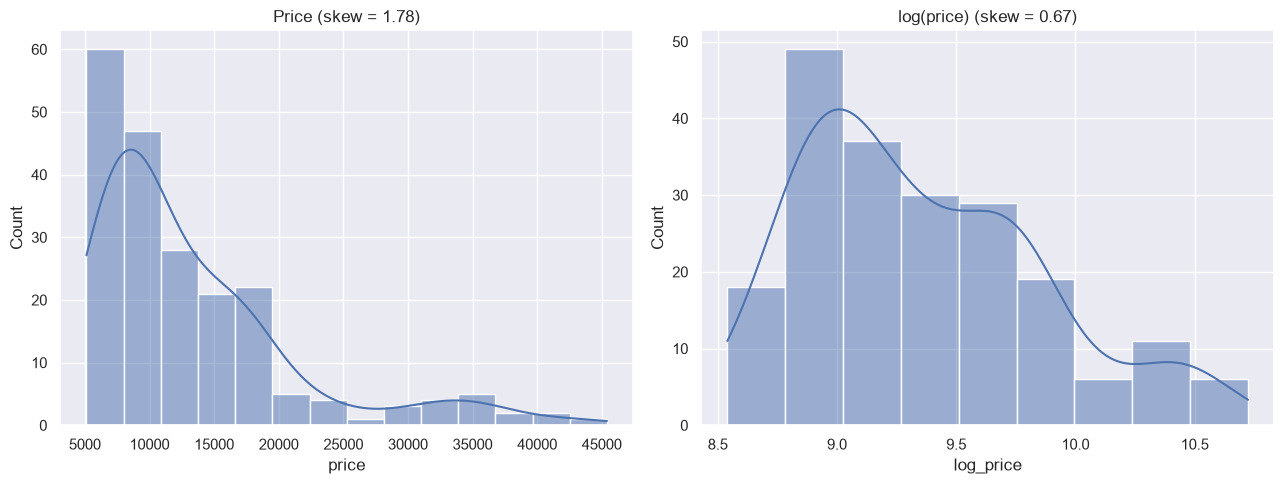

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df_auto['price'], kde=True, ax=axes[0])
axes[0].set_title(f"Price (skew = {df_auto['price'].skew():.2f})")
sns.histplot(df_auto['log_price'], kde=True, ax=axes[1])
axes[1].set_title(f"log(price) (skew = {df_auto['log_price'].skew():.2f})")
plt.tight_layout()
plt.show()

Price is strongly right-skewed: most cars cost \$6k–\$20k, and a long tail of luxury cars reaches \$45k. On the log scale the distribution is much more symmetric. Regression does not need the target itself to be normal, but a skewed target like this usually produces errors that grow with price. Section 6 checks whether that happens.

## 4.2 Categorical features vs price

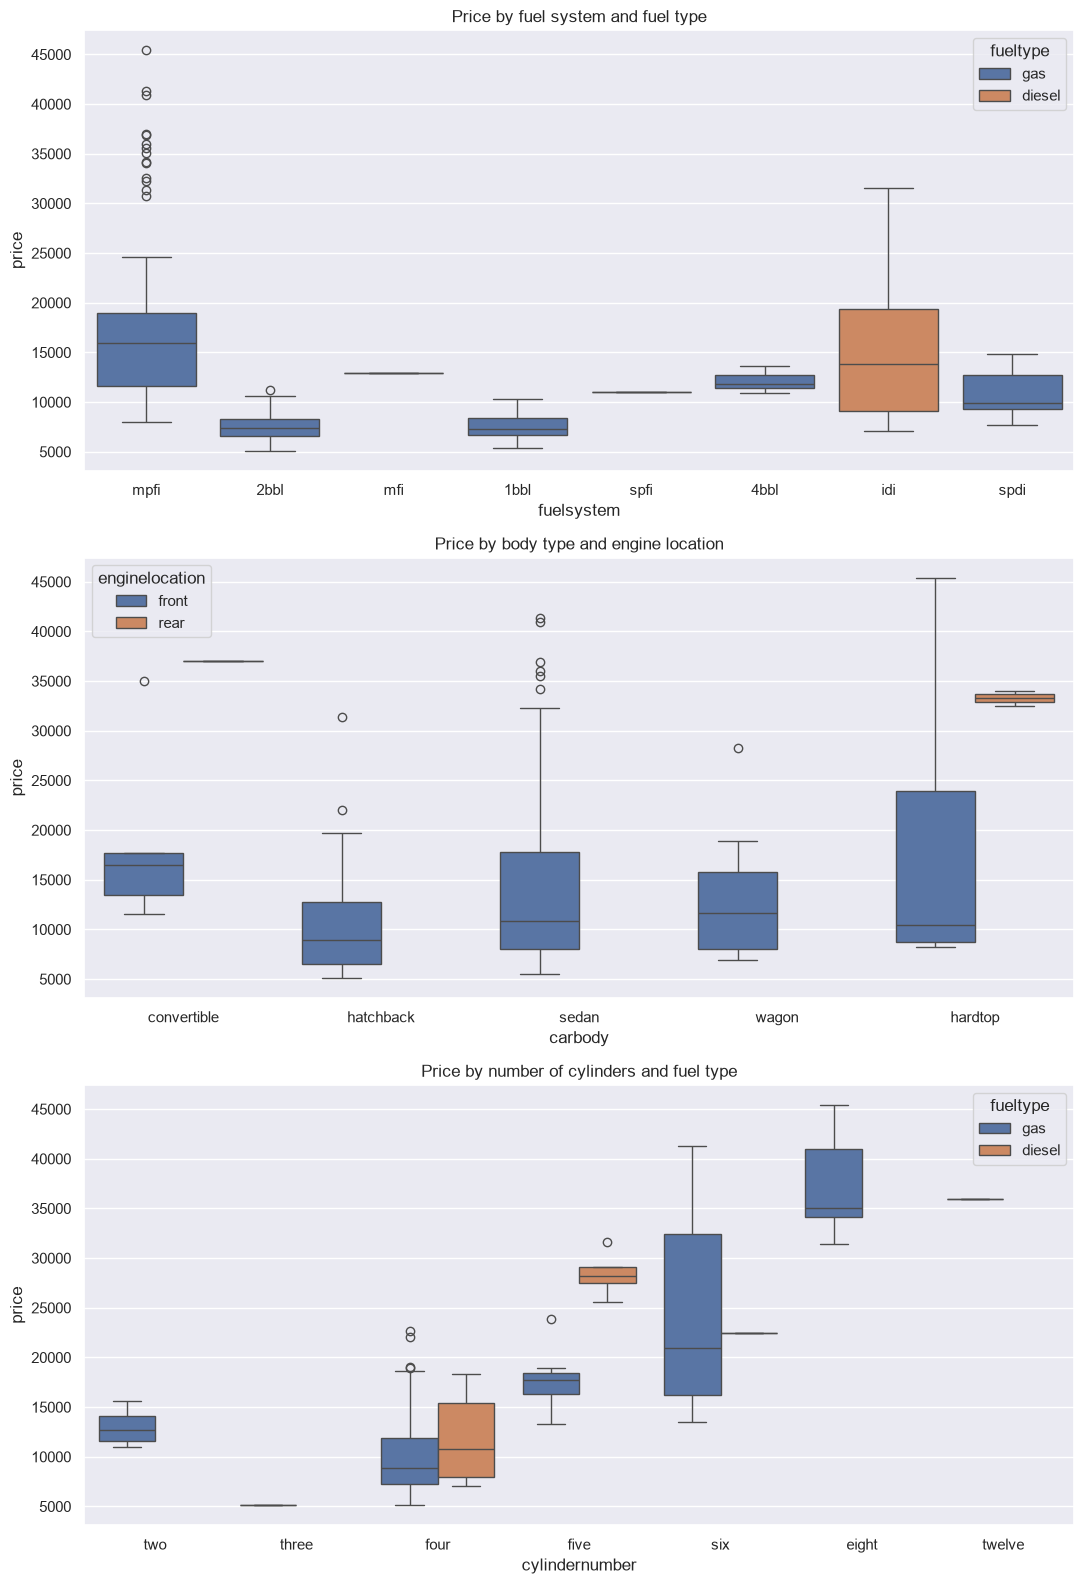

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(11, 16))
sns.boxplot(data=df_auto, x='fuelsystem', y='price', hue='fueltype', ax=axes[0])
axes[0].set_title('Price by fuel system and fuel type')
sns.boxplot(data=df_auto, x='carbody', y='price', hue='enginelocation', ax=axes[1])
axes[1].set_title('Price by body type and engine location')
sns.boxplot(data=df_auto, x='cylindernumber', y='price', hue='fueltype',
            order=['two', 'three', 'four', 'five', 'six', 'eight', 'twelve'], ax=axes[2])
axes[2].set_title('Price by number of cylinders and fuel type')
plt.tight_layout()
plt.show()

In [10]:
# Group sizes matter when reading the box plots above
for col in ['fueltype', 'enginelocation', 'carbody', 'cylindernumber']:
    print(df_auto[col].value_counts().to_dict())

{'gas': 185, 'diesel': 20}
{'front': 202, 'rear': 3}
{'sedan': 96, 'hatchback': 70, 'wagon': 25, 'hardtop': 8, 'convertible': 6}
{'four': 159, 'six': 24, 'five': 11, 'eight': 5, 'two': 4, 'three': 1, 'twelve': 1}


- **Fuel system:** multi-point injection (`mpfi`) cars have the highest median price and most of the expensive outliers. Carburettor cars (`1bbl`, `2bbl`) are the cheapest. All 20 diesel cars use `idi`.
- **Body type:** hatchbacks are the cheapest. Rear-engine cars are much more expensive (median about \$34k), but there are only **3** of them, so that pattern is weak evidence.
- **Cylinders:** price rises with cylinder count (four, then six, then eight). The groups with two, three and twelve cylinders have only 4, 1 and 1 cars.

## 4.3 Price by brand

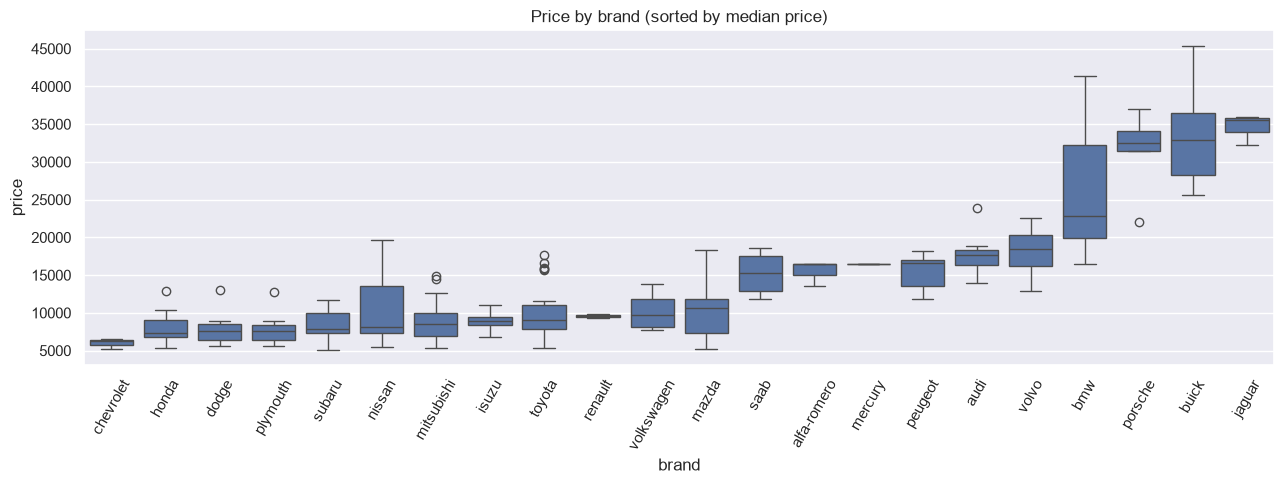

,count,median
brand,,
audi,7,"17,710.0000"
volvo,11,"18,420.0000"
bmw,8,"22,835.0000"
porsche,5,"32,528.0000"
buick,8,"32,892.0000"
jaguar,3,"35,550.0000"


In [11]:
brand_order = df_auto.groupby('brand')['price'].median().sort_values().index
plt.figure(figsize=(13, 5))
sns.boxplot(data=df_auto, x='brand', y='price', order=brand_order)
plt.xticks(rotation=60)
plt.title('Price by brand (sorted by median price)')
plt.tight_layout()
plt.show()

df_auto.groupby('brand')['price'].agg(['count', 'median']).sort_values('median').tail(6)

Brand is a strong price driver. Median prices run from about \$6k (Chevrolet) to over \$35k (Jaguar). Many brands have only a handful of cars, so one dummy variable per brand (21 dummies for 205 cars) would be unstable. Section 7.2 groups brands into **tiers** instead.

*Data-quality note:* the 8 cars labelled `buick` have a median price of about \$33k, which puts them in the same group as Porsche and Jaguar. The labels are kept as they are. The tiers are based on price, not on the name, so these cars are handled consistently either way.

## 4.4 Correlations between numeric features

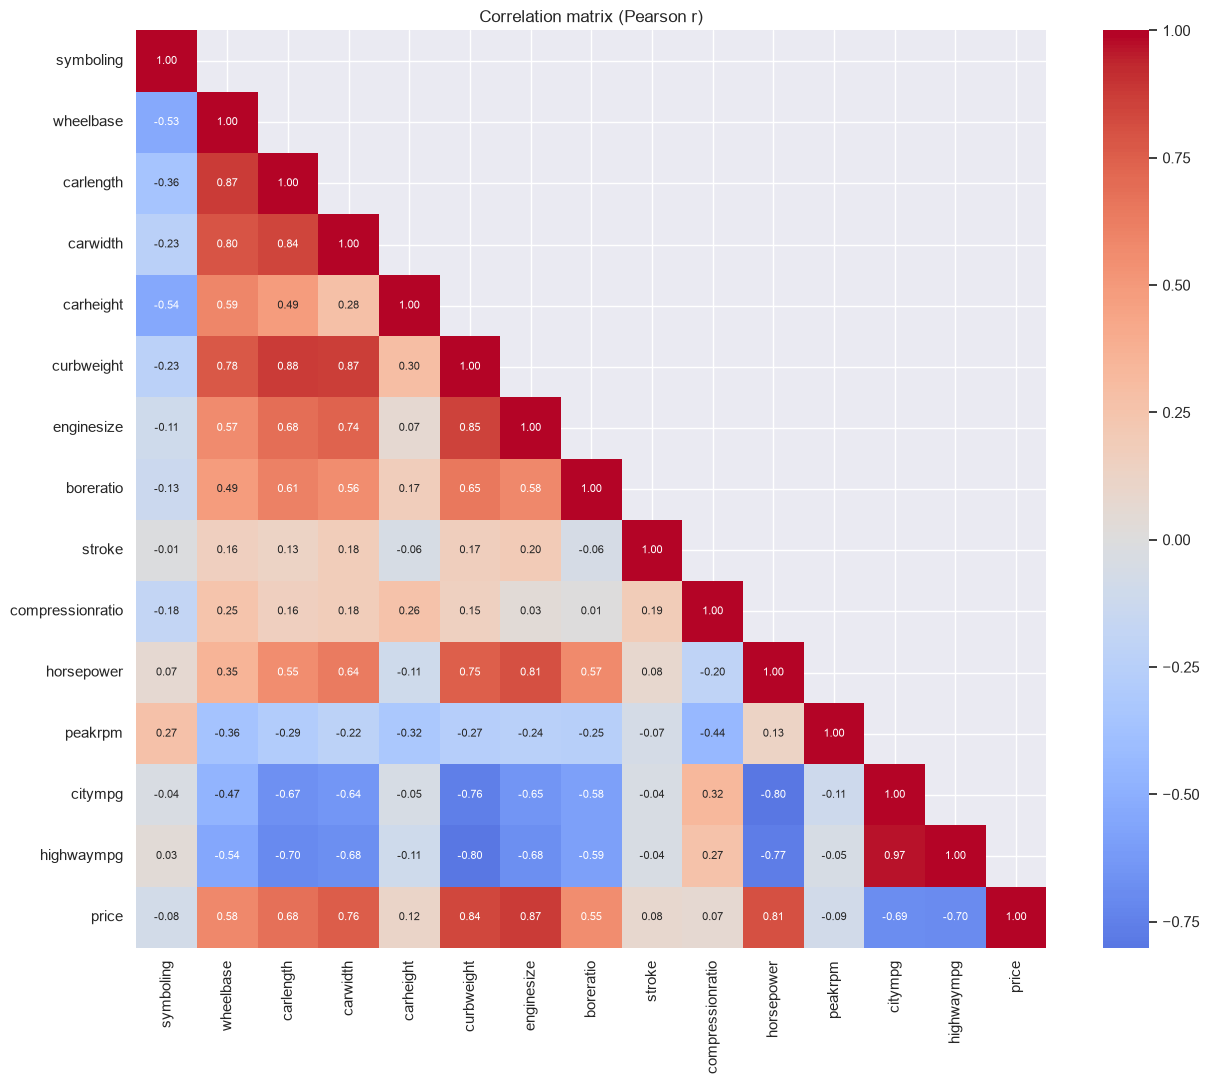

In [12]:
corr = df_auto[num_col].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # hide the duplicate upper triangle
plt.figure(figsize=(13, 11))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Correlation matrix (Pearson r)')
plt.tight_layout()
plt.show()

In [13]:
corr['price'].drop('price').sort_values(ascending=False).to_frame('r with price')

,r with price
enginesize,0.8741
curbweight,0.8353
horsepower,0.8081
carwidth,0.7593
carlength,0.6829
wheelbase,0.5778
boreratio,0.5532
carheight,0.1193
stroke,0.0794
compressionratio,0.0680


`enginesize` (0.87), `curbweight` (0.84) and `horsepower` (0.81) have the strongest positive correlations with price, which is why the original analysis chose them. Fuel economy (`citympg`, `highwaympg`) is strongly **negative**, because bigger and more expensive cars use more fuel.

The predictors are also highly correlated **with each other**, for example `citympg` vs `highwaympg` (0.97) and `curbweight` vs `enginesize` (0.85). This is a warning sign for multicollinearity, which Section 6.1 measures with VIF.

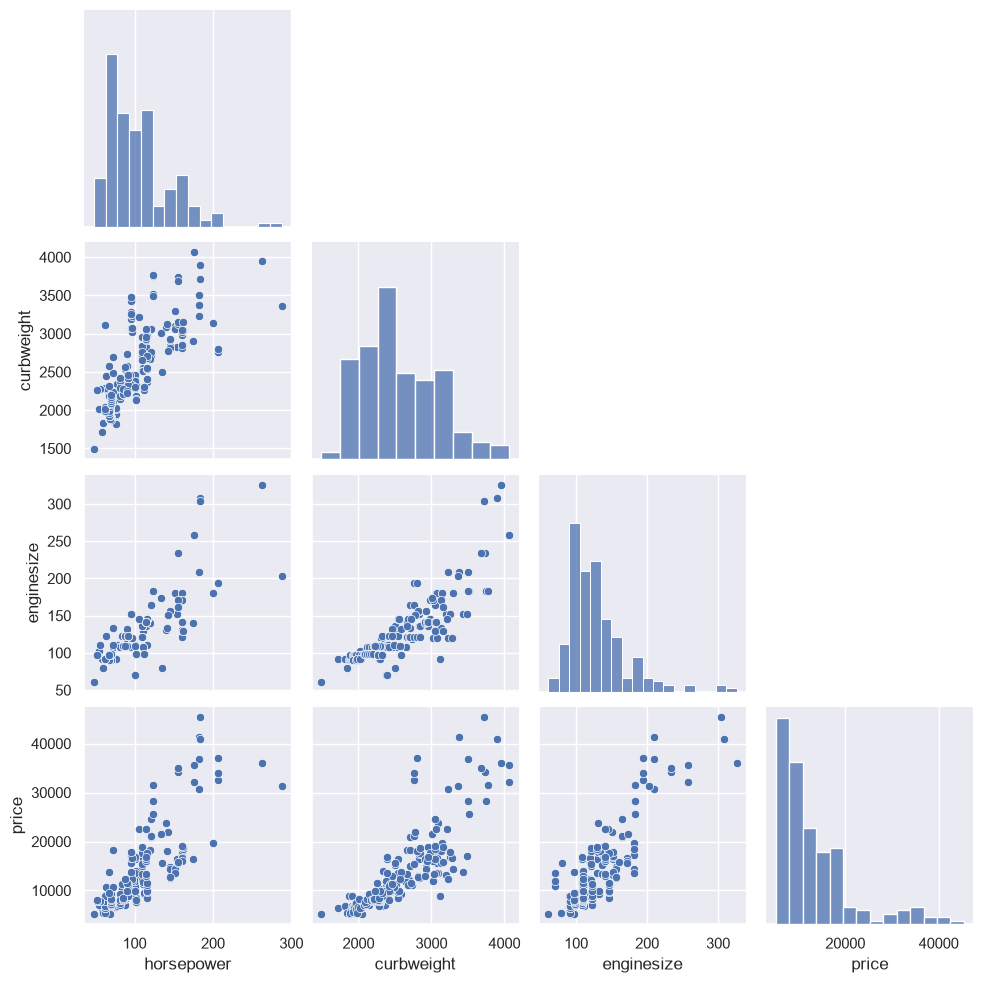

In [14]:
model_features = ['horsepower', 'curbweight', 'enginesize']
sns.pairplot(df_auto[model_features + ['price']], corner=True)
plt.show()

All three features have a clear upward relationship with price, and the scatter widens as price rises.

# 5. Train/test split

The test set is set aside **before** any model is fitted, so the final evaluation uses cars the models have never seen. Every model in Sections 5–8 is fitted on the training set only. Models are compared with cross-validation on the training set, and the test set is used once, in Section 9.

In [15]:
train_df, test_df = train_test_split(df_auto, test_size=0.2, random_state=RANDOM_STATE)
print(f"Training set: {len(train_df)} cars | Test set: {len(test_df)} cars")

Training set: 164 cars | Test set: 41 cars


## 5.1 Helper functions

- `fit_brand_tiers` learns brand tiers from the median price of each brand **in the data it is given**. Calling it on training data only keeps test prices from leaking into the features.
- `predict_price` turns log-scale predictions back into dollars. It multiplies by Duan's smearing factor, the mean of exp(residual), because exp(mean of log) underestimates the mean price.
- `cross_validate` runs repeated 5-fold CV and re-learns the brand tiers inside every fold.

In [16]:
TIER_CUTS = [0, 12_000, 20_000, np.inf]
TIER_LABELS = ['budget', 'mid', 'luxury']


def fit_brand_tiers(data):
    """Map each brand to a price tier using that brand's median price in `data`."""
    brand_median = data.groupby('brand')['price'].median()
    return pd.cut(brand_median, TIER_CUTS, labels=TIER_LABELS).astype(str).to_dict()


def add_tier(data, tier_map):
    data = data.copy()
    data['tier'] = data['brand'].map(tier_map).fillna('mid')  # a brand unseen in training falls back to 'mid'
    return data


def predict_price(fit, data):
    """Predict price in dollars, back-transforming log-price models with Duan's smearing factor."""
    pred = fit.predict(data)
    if fit.model.endog_names == 'log_price':
        pred = np.exp(pred) * np.mean(np.exp(fit.resid))
    return pred


def price_metrics(actual, pred):
    return {
        'R2': 1 - ((actual - pred) ** 2).sum() / ((actual - actual.mean()) ** 2).sum(),
        'RMSE': np.sqrt(np.mean((actual - pred) ** 2)),
        'MAE': np.mean(np.abs(actual - pred)),
        'MAPE %': 100 * np.mean(np.abs(actual - pred) / actual),
    }


def cross_validate(formula, data, n_splits=5, n_repeats=5):
    """Repeated k-fold CV of a statsmodels formula; scores are in dollars."""
    folds = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=RANDOM_STATE)
    scores = []
    for fit_idx, val_idx in folds.split(data):
        fit_part, val_part = data.iloc[fit_idx], data.iloc[val_idx]
        tier_map = fit_brand_tiers(fit_part)
        fit = smf.ols(formula, data=add_tier(fit_part, tier_map)).fit()
        val_part = add_tier(val_part, tier_map)
        scores.append(price_metrics(val_part['price'], predict_price(fit, val_part)))
    scores = pd.DataFrame(scores)
    return {'CV RMSE': scores['RMSE'].mean(), 'CV RMSE sd': scores['RMSE'].std(), 'CV MAPE %': scores['MAPE %'].mean()}


def vif_table(fit):
    exog = fit.model.exog
    names = fit.model.exog_names
    return pd.Series([variance_inflation_factor(exog, i) for i in range(exog.shape[1])],
                     index=names, name='VIF').drop('Intercept')

# 6. Baseline models (from the original analysis)

These are the three ordinary least squares (OLS) models from the original project, now fitted on the training set. The statsmodels formula API adds the intercept automatically.

In [17]:
baseline_formulas = {
    'Model 1: hp': 'price ~ horsepower',
    'Model 2: weight + engine': 'price ~ curbweight + enginesize',
    'Model 3: hp + weight + engine': 'price ~ horsepower + curbweight + enginesize',
}
baseline_fits = {name: smf.ols(f, data=train_df).fit() for name, f in baseline_formulas.items()}

pd.DataFrame({
    name: {'R2': fit.rsquared, 'Adj R2': fit.rsquared_adj, 'AIC': fit.aic, 'BIC': fit.bic, 'F p-value': fit.f_pvalue}
    for name, fit in baseline_fits.items()
}).T

,R2,Adj R2,AIC,BIC,F p-value
Model 1: hp,0.6577,0.6556,"3,229.8166","3,236.0163",0.0000
Model 2: weight + engine,0.7839,0.7812,"3,156.3935","3,165.6931",0.0000
Model 3: hp + weight + engine,0.8107,0.8072,"3,136.6396","3,149.0391",0.0000


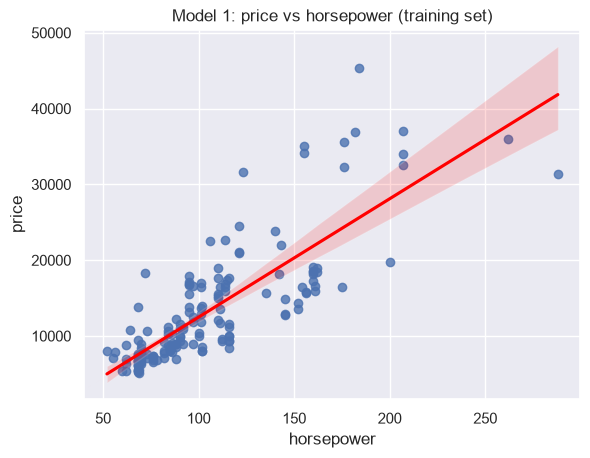

In [18]:
sns.regplot(data=train_df, x='horsepower', y='price', line_kws={'color': 'red'})
plt.title('Model 1: price vs horsepower (training set)')
plt.show()

In [19]:
mlr3 = baseline_fits['Model 3: hp + weight + engine']
print(mlr3.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.811
Model:                            OLS   Adj. R-squared:                  0.807
Method:                 Least Squares   F-statistic:                     228.5
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           1.34e-57
Time:                        18:40:00   Log-Likelihood:                -1564.3
No. Observations:                 164   AIC:                             3137.
Df Residuals:                     160   BIC:                             3149.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1.313e+04   1457.456     -9.010      0.0

Every criterion improves from Model 1 to Model 3 (higher adjusted R², lower AIC and BIC), so each added feature contributes something. Two things to keep in mind when reading the Model 3 coefficients:

- The horsepower coefficient is much smaller than in Model 1. On its own, horsepower also picks up the effect of the engine size and weight that come with it (omitted variable bias). In Model 3 each coefficient shows only that feature's **own** contribution, holding the other two constant.
- The large condition number warning is mostly a **scale** effect: curb weight is in the thousands while the intercept column is 1. VIF (next section) is the better test for multicollinearity.

## 6.1 Diagnostics for Model 3

### Multicollinearity (VIF)

In [20]:
vif_table(mlr3).to_frame()

,VIF
horsepower,2.9148
curbweight,3.4131
enginesize,4.5648


VIF = 1 / (1 − R²) from regressing each predictor on the others. Values between 3 and 5 mean **moderate** multicollinearity: the predictors overlap, but each still carries its own information. The usual warning threshold is 5–10.

### Which feature matters most? (standardised coefficients)

In [21]:
# Raw coefficients can't be compared because the units differ (pounds vs horsepower vs cubic inches).
# Multiplying by each feature's standard deviation gives the dollar effect of a typical (1 SD) change.
coef = mlr3.params.drop('Intercept')
feature_sd = train_df[coef.index].std()
pd.DataFrame({
    'coef': coef,
    'feature SD': feature_sd,
    'effect of +1 SD ($)': coef * feature_sd,
    'standardised beta': coef * feature_sd / train_df['price'].std(),
}).sort_values('standardised beta', ascending=False)

,coef,feature SD,effect of +1 SD ($),standardised beta
enginesize,77.7402,40.4690,"3,146.0711",0.4061
curbweight,4.2588,511.9355,"2,180.2078",0.2815
horsepower,53.8648,40.2281,"2,166.8768",0.2797


On a common scale **engine size has the largest effect**, and curb weight and horsepower are about equal (around \$2,200 each for a 1 SD increase). The raw coefficients suggest something quite different, horsepower at \$54 per unit vs curb weight at \$4 per pound, only because the units differ.

### Residual checks

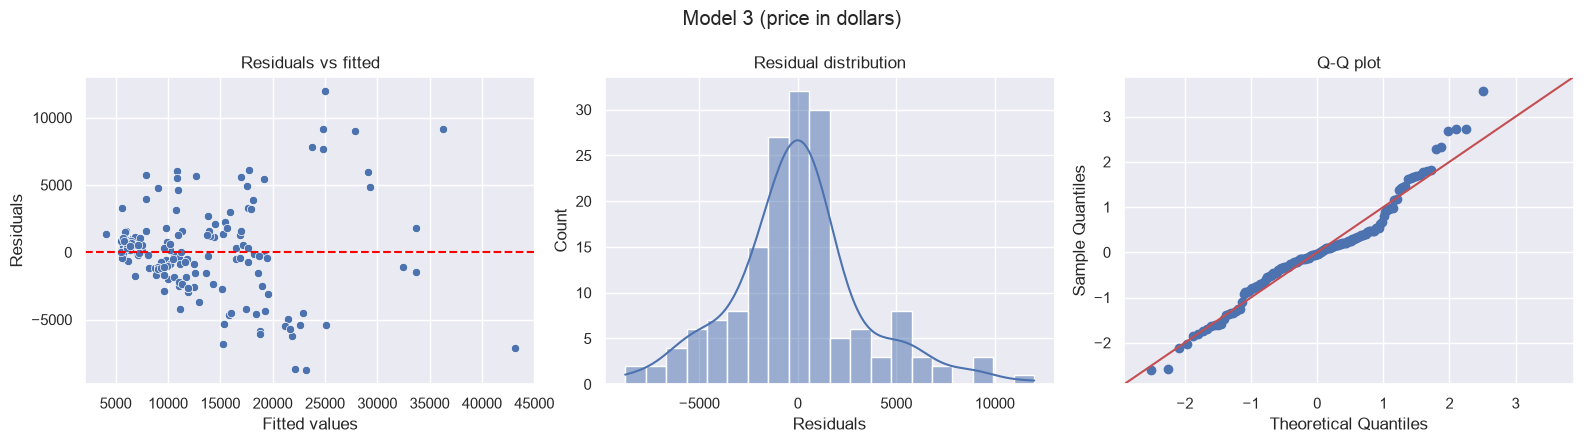

,Model 3
Breusch-Pagan p (constant variance),0.0000
Jarque-Bera p (normal residuals),0.0002
Residual skew,0.4385
Residual kurtosis (normal = 3),4.3124


In [22]:
def residual_plots(fit, title):
    fitted, resid = fit.fittedvalues, fit.resid
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    sns.scatterplot(x=fitted, y=resid, ax=axes[0])
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set(xlabel='Fitted values', ylabel='Residuals', title='Residuals vs fitted')
    sns.histplot(resid, kde=True, ax=axes[1])
    axes[1].set(xlabel='Residuals', title='Residual distribution')
    sm.qqplot(resid, line='45', fit=True, ax=axes[2])
    axes[2].set_title('Q-Q plot')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def assumption_tests(fit):
    jb_stat, jb_p = stats.jarque_bera(fit.resid)
    return pd.Series({
        'Breusch-Pagan p (constant variance)': het_breuschpagan(fit.resid, fit.model.exog)[1],
        'Jarque-Bera p (normal residuals)': jb_p,
        'Residual skew': stats.skew(fit.resid),
        'Residual kurtosis (normal = 3)': stats.kurtosis(fit.resid, fisher=False),
    })


residual_plots(mlr3, 'Model 3 (price in dollars)')
assumption_tests(mlr3).to_frame('Model 3')

- **Constant variance fails.** The residuals fan out as the fitted price rises (a funnel shape), and the Breusch–Pagan test rejects constant variance. The coefficients are still unbiased, but the ordinary standard errors and p-values can't be trusted.
- **Normality fails.** The residuals have a long right tail (the model badly under-predicts some expensive cars), and Jarque–Bera rejects normality.

In [23]:
# Do the conclusions survive heteroscedasticity-robust (HC3) standard errors?
robust3 = mlr3.get_robustcov_results(cov_type='HC3')
pd.DataFrame({'ordinary p': mlr3.pvalues, 'HC3 robust p': robust3.pvalues}, index=mlr3.params.index)

,ordinary p,HC3 robust p
Intercept,0.0000,0.0000
horsepower,0.0000,0.0013
curbweight,0.0000,0.0028
enginesize,0.0000,0.0027


All three features stay significant with robust standard errors, so the baseline conclusion holds. The variance problem still points to a better specification, which Section 7 builds.

**About the Durbin–Watson statistic.** It tests whether neighbouring rows have related errors. The original notebook fitted on the CSV in file order, which is sorted by brand, and got DW ≈ 0.75: cars of the same brand sit next to each other and share the same unexplained brand premium. That points to a **missing brand variable**, not a time-series problem. The training set here is shuffled, so DW carries no meaning and is ignored.

# 7. Improving the model

The diagnostics point to three fixes:

1. **Log-transform price**, to stabilise the error variance and reduce skew.
2. **Add brand tier**, the biggest missing driver of price.
3. **Add body type**, which the box plots suggest matters.

Each step is checked on the training data, and all models are compared with cross-validation in Section 8.

## 7.1 Model 4: log(price) with the same three features

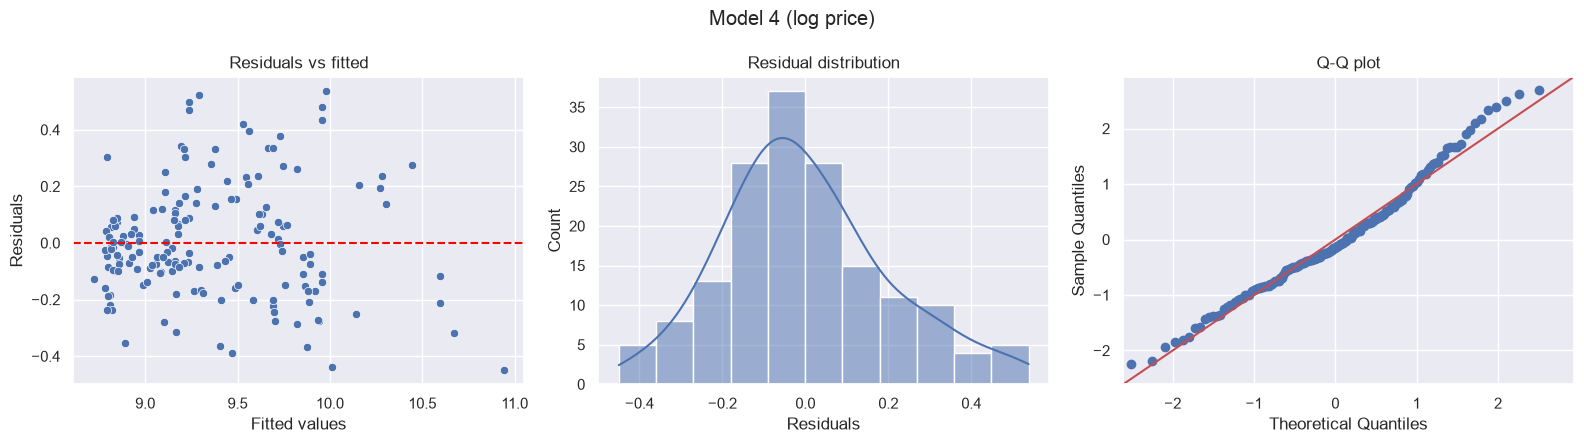

,Model 4
Breusch-Pagan p (constant variance),0.0000
Jarque-Bera p (normal residuals),0.0559
Residual skew,0.4581
Residual kurtosis (normal = 3),3.0673


In [24]:
mlr4 = smf.ols('log_price ~ horsepower + curbweight + enginesize', data=train_df).fit()
residual_plots(mlr4, 'Model 4 (log price)')
assumption_tests(mlr4).to_frame('Model 4')

The log transform makes the residuals much closer to normal (Jarque–Bera no longer rejects, and kurtosis drops to about 3). **It does not fix the unequal variance**: Breusch–Pagan still rejects. The remaining structure comes from brands, because cars from the same brand sit consistently above or below the line. That is the next fix.

## 7.2 Model 5: add brand tier

In [25]:
tier_map = fit_brand_tiers(train_df)  # learned from training prices only
train_df = add_tier(train_df, tier_map)
test_df = add_tier(test_df, tier_map)

for tier in TIER_LABELS:
    print(f"{tier:>7}: {', '.join(sorted(b for b, t in tier_map.items() if t == tier))}")

 budget: chevrolet, dodge, honda, isuzu, mazda, mitsubishi, nissan, plymouth, renault, subaru, toyota, volkswagen
    mid: alfa-romero, audi, mercury, peugeot, saab, volvo
 luxury: bmw, buick, jaguar, porsche


In [26]:
TIER = "C(tier, Treatment('budget'))"  # budget brands are the reference group
mlr5 = smf.ols(f'log_price ~ horsepower + curbweight + enginesize + {TIER}', data=train_df).fit()
print(mlr5.summary().tables[1])
vif_table(mlr5).to_frame()

                                             coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------
Intercept                                  7.7509      0.084     92.101      0.000       7.585       7.917
C(tier, Treatment('budget'))[T.luxury]     0.5380      0.057      9.430      0.000       0.425       0.651
C(tier, Treatment('budget'))[T.mid]        0.2182      0.041      5.289      0.000       0.137       0.300
horsepower                                 0.0038      0.001      6.974      0.000       0.003       0.005
curbweight                                 0.0005   5.73e-05      8.441      0.000       0.000       0.001
enginesize                                -0.0010      0.001     -1.281      0.202      -0.003       0.001


,VIF
"C(tier, Treatment('budget'))[T.luxury]",2.0283
"C(tier, Treatment('budget'))[T.mid]",1.7836
horsepower,2.9796
curbweight,5.4582
enginesize,6.7527


Both tier dummies are strongly significant, and with brand tier in the model **the variance problem is gone** (Breusch–Pagan p ≈ 0.32, see Section 8). **Engine size is no longer significant**, and its VIF rises above 5. Most of what engine size seemed to explain was really the difference between luxury and budget brands, which tend to have bigger engines. Model 6 drops it.

## 7.3 Model 6: replace engine size with body type

In [27]:
BODY = "C(carbody, Treatment('sedan'))"  # sedan, the most common body type, is the reference group
formula6 = f'log_price ~ horsepower + curbweight + {TIER} + {BODY}'
mlr6 = smf.ols(formula6, data=train_df).fit()
print(mlr6.summary().tables[1])
vif_table(mlr6).to_frame()

                                                    coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------
Intercept                                         7.7574      0.082     94.225      0.000       7.595       7.920
C(tier, Treatment('budget'))[T.luxury]            0.4411      0.054      8.095      0.000       0.333       0.549
C(tier, Treatment('budget'))[T.mid]               0.2094      0.038      5.553      0.000       0.135       0.284
C(carbody, Treatment('sedan'))[T.convertible]     0.1862      0.066      2.831      0.005       0.056       0.316
C(carbody, Treatment('sedan'))[T.hardtop]         0.0768      0.076      1.016      0.311      -0.073       0.226
C(carbody, Treatment('sedan'))[T.hatchback]      -0.0541      0.029     -1.834      0.069      -0.112       0.004
C(carbody, Treatment('sedan'))[T.wagon]          -0.1080      0.041     -2.615      0.01

,VIF
"C(tier, Treatment('budget'))[T.luxury]",2.0333
"C(tier, Treatment('budget'))[T.mid]",1.6370
"C(carbody, Treatment('sedan'))[T.convertible]",1.0693
"C(carbody, Treatment('sedan'))[T.hardtop]",1.1830
"C(carbody, Treatment('sedan'))[T.hatchback]",1.3701
"C(carbody, Treatment('sedan'))[T.wagon]",1.2236
horsepower,2.9415
curbweight,3.3886


All VIFs are now low (below 5), so multicollinearity is no longer a concern.

## 7.4 Interaction effects

An interaction tests whether the effect of one feature depends on another. A natural question is whether an extra unit of horsepower is worth more in a luxury car than in a budget car. The partial F-test compares the model with and without the interaction terms.

In [28]:
formula6_int = formula6 + f' + horsepower:{TIER}'
mlr6_int = smf.ols(formula6_int, data=train_df).fit()
f_stat, f_p, df_diff = mlr6_int.compare_f_test(mlr6)
print(f"Partial F-test for horsepower x tier: F = {f_stat:.2f}, p = {f_p:.4f}, extra terms = {df_diff:.0f}")
print(mlr6_int.summary().tables[1])

Partial F-test for horsepower x tier: F = 4.54, p = 0.0121, extra terms = 2
                                                        coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------
Intercept                                             7.7361      0.081     94.962      0.000       7.575       7.897
C(tier, Treatment('budget'))[T.luxury]                0.8286      0.140      5.929      0.000       0.553       1.105
C(tier, Treatment('budget'))[T.mid]                   0.2797      0.155      1.808      0.073      -0.026       0.585
C(carbody, Treatment('sedan'))[T.convertible]         0.1890      0.065      2.923      0.004       0.061       0.317
C(carbody, Treatment('sedan'))[T.hardtop]             0.0970      0.075      1.300      0.196      -0.050       0.245
C(carbody, Treatment('sedan'))[T.hatchback]          -0.0591      0.029     -2.045      0.043     

The interaction is significant (partial F-test p ≈ 0.01), driven by the luxury tier. The horsepower slope for luxury brands is clearly **smaller** than for budget brands. In other words, extra horsepower raises price less for luxury cars, where the brand already sets a high price. The mid-tier difference is not significant.

# 8. Model comparison with cross-validation

Each candidate model is scored with **5-fold cross-validation repeated 5 times** (25 fits) on the training set. Brand tiers are re-learned inside each fold. All errors are in dollars, so the log and linear models are compared fairly. AIC is only comparable between models with the same target, so it is not used here.

In [29]:
candidates = {
    'Model 3: price ~ hp + weight + engine': 'price ~ horsepower + curbweight + enginesize',
    'Model 4: log ~ hp + weight + engine': 'log_price ~ horsepower + curbweight + enginesize',
    'Model 5: Model 4 + tier': f'log_price ~ horsepower + curbweight + enginesize + {TIER}',
    'Model 6: log ~ hp + weight + tier + body': formula6,
    'Model 6 + hp x tier interaction': formula6_int,
    'Model 6 on price (not log)': formula6.replace('log_price', 'price'),
}
cv_base = train_df.drop(columns=['tier'])  # tiers are re-learned inside each fold
comparison = pd.DataFrame({name: cross_validate(f, cv_base) for name, f in candidates.items()}).T
comparison['Adj R2 (train)'] = [smf.ols(f, data=train_df).fit().rsquared_adj for f in candidates.values()]
comparison['Breusch-Pagan p'] = [
    het_breuschpagan((fit := smf.ols(f, data=train_df).fit()).resid, fit.model.exog)[1] for f in candidates.values()
]
comparison.round(3)

,CV RMSE,CV RMSE sd,CV MAPE %,Adj R2 (train),Breusch-Pagan p
Model 3: price ~ hp + weight + engine,"3,510.0890",485.3510,17.8040,0.8070,0.0000
Model 4: log ~ hp + weight + engine,"4,285.7210","1,112.5020",16.9310,0.8350,0.0000
Model 5: Model 4 + tier,"3,480.2970","1,127.1220",12.9470,0.8970,0.3150
Model 6: log ~ hp + weight + tier + body,"3,125.2730",852.0360,12.5990,0.9060,0.5290
Model 6 + hp x tier interaction,"2,826.7480",602.8110,12.2360,0.9100,0.1030
Model 6 on price (not log),"2,521.2070",804.4500,12.3700,0.9200,0.0000


**Reading the table** (lower CV RMSE and MAPE are better, and a Breusch–Pagan p above 0.05 means constant variance is plausible):

- **Log price alone (Model 4) makes dollar errors worse**, because back-transforming errors on expensive cars magnifies them. The log transform only pays off once brand tier is in the model (Model 5).
- **Brand tier is the biggest single improvement.** Percentage error (MAPE) falls from about 17% to 13%.
- **The interaction model is the best log model:** lowest CV RMSE (about \$2,830), lowest MAPE (12.2%), lower fold-to-fold variability, and constant variance holds.
- **The same features on raw price** reach a lower dollar RMSE, but they fail the constant-variance test, so their p-values and confidence intervals would be unreliable. Because this project is about **explaining** price as well as predicting it, the log model with valid inference is chosen. The cost is about \$300 of CV RMSE, and the percentage errors are essentially the same.

**Final model:** `log(price) ~ horsepower + curbweight + brand tier + body type + horsepower × tier`.

# 9. Final model

In [30]:
final = smf.ols(formula6_int, data=train_df).fit(cov_type='HC3')  # robust standard errors as a safeguard
print(final.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.916
Model:                            OLS   Adj. R-squared:                  0.910
Method:                 Least Squares   F-statistic:                     195.3
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           9.30e-82
Time:                        18:40:03   Log-Likelihood:                 84.555
No. Observations:                 164   AIC:                            -147.1
Df Residuals:                     153   BIC:                            -113.0
Df Model:                          10                                         
Covariance Type:                  HC3                                         
                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------

### Interpreting the coefficients

In a log-price model a coefficient *b* means price changes by (e<sup>b</sup> − 1) × 100 percent, holding the other features constant. Because of the interaction, the horsepower effect differs by tier, so it is reported for each tier separately.

In [31]:
def pct(x):
    return (np.exp(x) - 1) * 100


rows = {}
# Categorical effects, relative to a budget-brand sedan with the same horsepower and weight.
# The tier main effects are left out: with the interaction, they describe a 0-hp car and mean nothing on their own.
for term in final.params.index:
    if term.startswith('C(carbody'):
        lo, hi = final.conf_int().loc[term]
        rows[term.split('[T.')[1].rstrip(']') + ' (vs sedan)'] = [pct(final.params[term]), pct(lo), pct(hi), final.pvalues[term]]

# Continuous effects for meaningful step sizes
INT = f'horsepower:{TIER}'
hp_slopes = {
    'budget': 'horsepower',
    'mid': f'horsepower + {INT}[T.mid]',
    'luxury': f'horsepower + {INT}[T.luxury]',
}
for tier, expr in hp_slopes.items():
    test = final.t_test(f'10 * ({expr}) = 0')
    lo, hi = np.asarray(test.conf_int()).ravel()
    rows[f'+10 horsepower ({tier} brand)'] = [pct(test.effect.item()), pct(lo), pct(hi), float(test.pvalue)]
lo, hi = final.conf_int().loc['curbweight']
rows['+100 lb curb weight'] = [pct(100 * final.params['curbweight']), pct(100 * lo), pct(100 * hi), final.pvalues['curbweight']]

pd.DataFrame(rows, index=['effect on price %', 'CI low %', 'CI high %', 'p-value']).T.round(3)

,effect on price %,CI low %,CI high %,p-value
convertible (vs sedan),20.8030,4.6900,39.3970,0.0100
hardtop (vs sedan),10.1890,-18.8650,49.6470,0.5340
hatchback (vs sedan),-5.7390,-10.5850,-0.6300,0.0280
wagon (vs sedan),-9.5760,-16.8520,-1.6630,0.0190
+10 horsepower (budget brand),4.4730,2.8300,6.1420,0.0000
+10 horsepower (mid brand),3.7540,1.9180,5.6240,0.0000
+10 horsepower (luxury brand),1.7410,-0.2830,3.8060,0.0920
+100 lb curb weight,4.3960,3.1300,5.6780,0.0000


In [32]:
# Brand-tier premium at a typical horsepower (the training median)
hp_typical = train_df['horsepower'].median()
for tier in ['mid', 'luxury']:
    test = final.t_test(f"{TIER}[T.{tier}] + {hp_typical} * {INT}[T.{tier}] = 0")
    lo, hi = np.asarray(test.conf_int()).ravel()
    print(f"{tier:>6} vs budget at {hp_typical:.0f} hp: {pct(test.effect.item()):+.1f}% (95% CI {pct(lo):+.1f}% to {pct(hi):+.1f}%)")

   mid vs budget at 95 hp: +23.9% (95% CI +10.2% to +39.2%)
luxury vs budget at 95 hp: +78.0% (95% CI +57.8% to +100.8%)


- **Brand tier is the largest effect.** At a typical 95 hp, a luxury-brand car costs about **78% more** than a comparable budget-brand car, and a mid-tier car about **24% more**.
- **Horsepower matters most for budget brands:** +10 hp adds about 4.5% to price for budget brands, 3.8% for mid-tier brands, and only about 1.7% for luxury brands (not significant on its own, p ≈ 0.09).
- **Curb weight:** each extra 100 lb adds about 4.4% to price.
- **Body type:** convertibles cost about 21% more than comparable sedans, while hatchbacks (−6%) and wagons (−10%) cost less. Hardtops are not significantly different from sedans (only 8 cars).
- These are **associations** in observational data, holding the other features constant. They are not causal effects.

### Final diagnostics

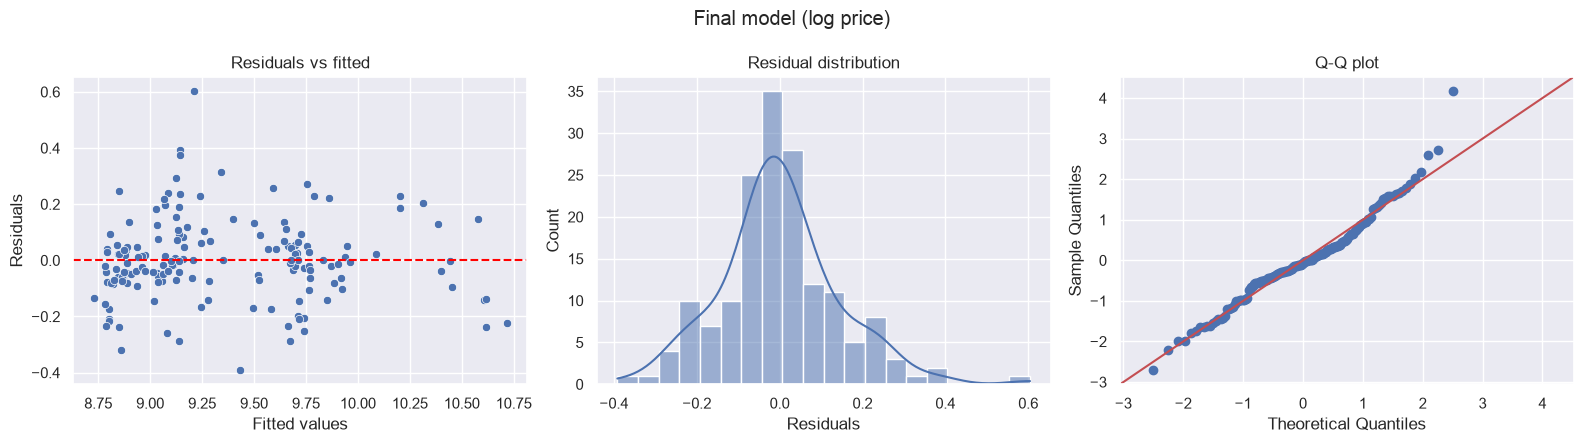

,Final model
Breusch-Pagan p (constant variance),0.1034
Jarque-Bera p (normal residuals),0.0000
Residual skew,0.5199
Residual kurtosis (normal = 3),4.5780


In [33]:
residual_plots(final, 'Final model (log price)')
assumption_tests(final).to_frame('Final model')

- **Constant variance now holds:** the funnel is gone and Breusch–Pagan no longer rejects (p ≈ 0.10, compared with p < 0.0001 for Model 3).
- **Normality is still rejected,** mainly because of a few cars in the tails (one point sits about 4 SD out on the Q-Q plot). With 164 cars the coefficient tests are fairly robust to mild non-normality, and the HC3 robust standard errors guard against the remaining problems.
- **Multicollinearity is low:** all VIFs are below 5 without the interaction terms (Section 7.3). Interaction terms always correlate with their parent terms, so their VIFs are not meaningful.

In [34]:
# Influential cars: Cook's distance above 4/n is the usual flag
influence = smf.ols(formula6_int, data=train_df).fit().get_influence()
cooks = pd.Series(influence.cooks_distance[0], index=train_df.index)
print(f"Cars above 4/n = {4 / len(train_df):.3f}: {(cooks > 4 / len(train_df)).sum()} of {len(train_df)}")
train_df.assign(cooks_d=cooks).nlargest(5, 'cooks_d')[['brand', 'carbody', 'horsepower', 'curbweight', 'price', 'cooks_d']]

Cars above 4/n = 0.024: 14 of 164


,brand,carbody,horsepower,curbweight,price,cooks_d
167,toyota,hardtop,116,2540,"8,449.0000",0.2603
49,jaguar,sedan,262,3950,"36,000.0000",0.1187
127,porsche,hardtop,207,2756,"34,028.0000",0.0943
128,porsche,convertible,207,2800,"37,028.0000",0.0805
66,mazda,sedan,72,2700,"18,344.0000",0.0770


Several cars exceed the 4/n rule of thumb, but the largest Cook’s distance is about 0.26, far below the level of 1 that would mean one car controls the fit. The most influential cars are genuine (a low-priced Toyota hardtop, a Jaguar, Porsches), so they are kept rather than deleted.

## 9.1 Test-set evaluation

In [35]:
test_results = pd.DataFrame({
    'Model 3 (baseline)': price_metrics(test_df['price'], predict_price(mlr3, test_df)),
    'Model 6 (no interaction)': price_metrics(test_df['price'], predict_price(mlr6, test_df)),
    'Final model': price_metrics(test_df['price'], predict_price(final, test_df)),
}).T
test_results.round(3)

,R2,RMSE,MAE,MAPE %
Model 3 (baseline),0.8210,"3,761.0820","2,722.1020",21.5500
Model 6 (no interaction),0.9380,"2,214.9030","1,403.4910",10.2920
Final model,0.9200,"2,513.0820","1,652.0160",11.2810


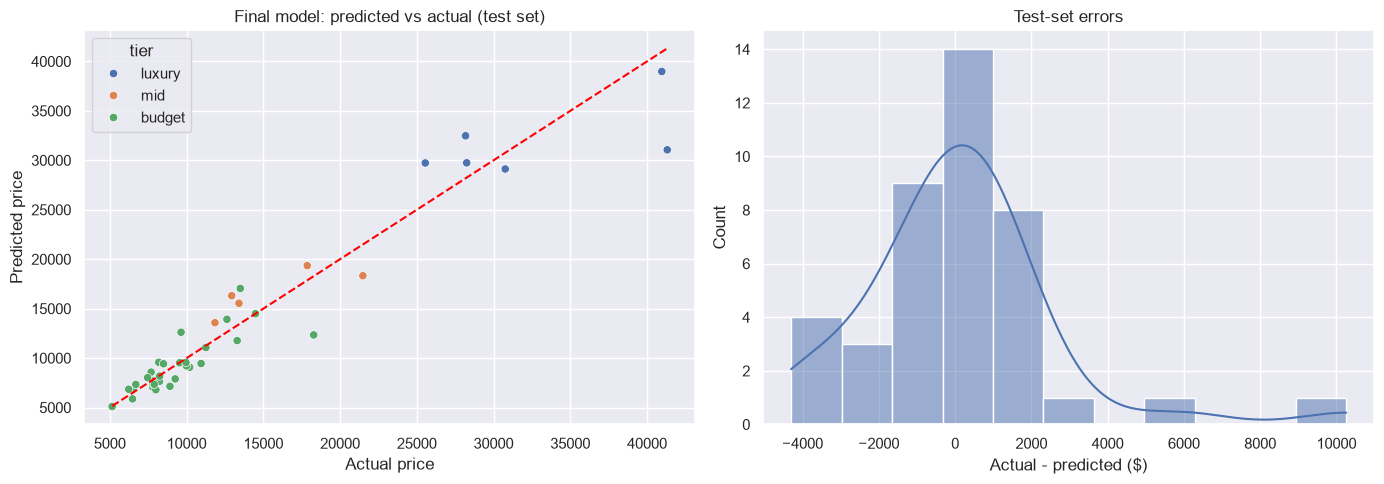

In [36]:
final_pred = predict_price(final, test_df)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=test_df['price'], y=final_pred, hue=test_df['tier'], ax=axes[0])
lims = [test_df['price'].min(), test_df['price'].max()]
axes[0].plot(lims, lims, color='red', linestyle='--')
axes[0].set(xlabel='Actual price', ylabel='Predicted price', title='Final model: predicted vs actual (test set)')
sns.histplot(test_df['price'] - final_pred, kde=True, ax=axes[1])
axes[1].set(xlabel='Actual - predicted ($)', title='Test-set errors')
plt.tight_layout()
plt.show()

On the 41 held-out cars, the final model cuts the baseline's error roughly in half: R² rises from 0.82 to 0.92, and the typical error (MAE) falls from about \$2,700 to \$1,650.

The simpler Model 6 (no interaction) happens to score a little better on this particular test set. The final model was chosen **before** looking at the test set, using 25 cross-validation fits where the interaction model was better. With only 41 test cars, a gap this size is within the noise (the CV RMSE varies by \$600–\$850 from fold to fold). Switching models now because of the test score would let the test set leak into model selection, so the choice stands. Both models clearly beat the baseline.

The largest misses are on luxury cars, which the predicted vs actual plot shows clearly. There are only 24 luxury cars in the whole dataset, so the model has little information about that segment.

# 10. Conclusions

**1. Which features significantly affect price?** Brand tier, horsepower, curb weight and body type, all at p < 0.05 with robust standard errors. Engine size is strongly correlated with price, but it adds nothing once brand tier and weight are in the model: its apparent effect came mostly from luxury brands having bigger engines.

**2. How important is each one?** Brand tier dominates: a luxury brand costs about 78% more than a comparable budget brand at typical horsepower. Next come curb weight (+4.4% per 100 lb, about +25% per standard deviation) and horsepower (+4.5% per 10 hp for budget brands). Body type has smaller effects (convertible +21%, wagon −10%).

**3. Can multiple linear regression predict price accurately?** Yes, within limits. The final model explains about 91% of the variation in log price on the training data. On unseen cars it reaches R² ≈ 0.92 with a typical error of about \$1,650 (about 11%), compared with R² ≈ 0.82 and about \$2,700 (about 22%) for the original three-feature model.

**4. Are there interaction effects?** Yes. Horsepower raises price much less for luxury brands than for budget brands (partial F-test p ≈ 0.01).

**What changed from the original analysis**

| Issue in the original | Fix |
|---|---|
| Models fitted and judged on the same data | 80/20 train/test split up front, plus repeated 5-fold CV for model selection |
| Errors grew with price (heteroscedasticity) | Log-price target and brand tier. Breusch–Pagan p went from < 0.0001 to about 0.10 |
| Categorical features ignored | Brand tier (learned from training prices only, so no leakage) and body type |
| Multicollinearity not measured | VIF tables. The final model's main effects all have VIF < 5 |
| Importance judged from raw coefficients | Standardised effects and percentage effects with confidence intervals |
| Interaction effects not tested | Horsepower × tier tested with a partial F-test |
| Residual plots without conclusions | Formal tests (Breusch–Pagan, Jarque–Bera), robust HC3 standard errors, Cook's distance |
| Brand typos fixed one by one; deprecated `distplot`; unused imports; warnings hidden | Lower-casing plus a typo map; `histplot`; only the imports that are used; warnings left on |

**Limitations**

- **Small, dated sample.** 205 cars (only 24 luxury), from the classic 1985 imports dataset. The coefficients describe that market, not today's.
- **Tier boundaries are a modelling choice.** The \$12k and \$20k cut-offs on brand median price are judgement calls. They are learned from training data only, but other cut-offs would give somewhat different numbers.
- **Residuals have heavier tails than a normal distribution,** so p-values close to 0.05 should be read with care.
- **Associations, not causes.** For example, the data cannot say whether adding horsepower to a given car would raise its market price.